Projet finance computationnelle 

Tache 1 : 

On ne peux télécharger les données historiques de Yahoo finance car depuis 2024 les telechargements ont été résérvé aux abonnées payants .
    

In [1]:
!pip install yfinance
import yfinance as yhoof
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [2]:
donnees = yhoof.download("NVDA", start="2000-01-01", end="2024-12-31", auto_adjust=False)
Cours_cloture_adj = donnees["Adj Close"]

print(Cours_cloture_adj.head())
print (Cours_cloture_adj.tail())

[*********************100%***********************]  1 of 1 completed

Ticker          NVDA
Date                
2000-01-03  0.089206
2000-01-04  0.086825
2000-01-05  0.083966
2000-01-06  0.078487
2000-01-07  0.079798
Ticker            NVDA
Date                  
2024-12-23  139.305832
2024-12-24  139.854416
2024-12-26  139.565155
2024-12-27  136.652756
2024-12-30  137.131516


1- Nettoyer et inspecter le fichier :

In [3]:
Cours_cloture_adj.info()  #infos général

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6288 entries, 2000-01-03 to 2024-12-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NVDA    6288 non-null   float64
dtypes: float64(1)
memory usage: 98.2 KB


In [4]:
Cours_cloture_adj.isna().sum()   #nbre de valeurs manquantes

Ticker
NVDA    0
dtype: int64

In [5]:
display(Cours_cloture_adj.min())
display(Cours_cloture_adj.max())

Ticker
NVDA    0.056178
dtype: float64

Ticker
NVDA    148.481583
dtype: float64

In [6]:
display(Cours_cloture_adj.index.min())
Cours_cloture_adj.index.max()

Timestamp('2000-01-03 00:00:00')

Timestamp('2024-12-30 00:00:00')

In [7]:
Cours_cloture_adj.agg(["min", "idxmin"])

Ticker,NVDA
min,0.056178
idxmin,2002-10-09 00:00:00


In [8]:
Cours_cloture_adj.agg(["max","idxmax"])

Ticker,NVDA
max,148.481583
idxmax,2024-11-07 00:00:00


2-Rendement disret et continu 
d'ici là on nomme dorénavant 
Cours_cloture_adj = St
Rendement discret =Rt
Rendement continu =rt

In [9]:
St = donnees["Adj Close"]

In [10]:
def Rendement_discret(St):
    i=1
    Rt=[]
    for i in range (1,len(St)):
       R =((St.iloc[i]-St.iloc[i-1])/St.iloc[i-1])*100
       Rt.append(R)
    return Rt
Rt=Rendement_discret(St)
print(Rt[:5])

[Ticker
NVDA   -2.670088
dtype: float64, Ticker
NVDA   -3.292156
dtype: float64, Ticker
NVDA   -6.525239
dtype: float64, Ticker
NVDA    1.669981
dtype: float64, Ticker
NVDA    3.282898
dtype: float64]


In [11]:
def Rendement_continu(St):
    i=1
    rt=[]
    for i in range (1,len(St)):
       R =(np.log(St.iloc[i])-np.log(St.iloc[i-1]))*100
       rt.append(R)
    return rt
rt=Rendement_continu(St)
print(rt[:5])

[Ticker
NVDA   -2.706382
dtype: float64, Ticker
NVDA   -3.347567
dtype: float64, Ticker
NVDA   -6.747872
dtype: float64, Ticker
NVDA    1.65619
dtype: float64, Ticker
NVDA    3.230162
dtype: float64]


2- Graphique et statistique : 

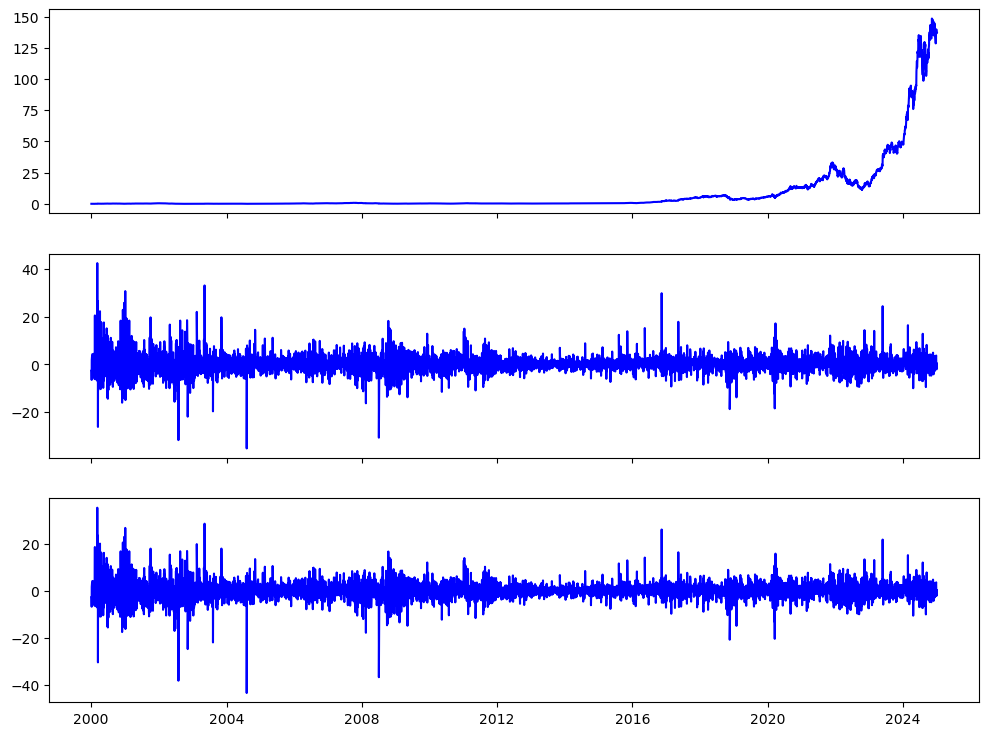

In [15]:
Rt_liste = Rendement_discret(St["NVDA"])
Rt = pd.Series(Rt_liste, index=St.index[1:])
rt_liste = Rendement_continu(St["NVDA"])
rt = pd.Series(rt_liste, index=St.index[1:])
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax1.plot(St.index,St, color="blue",label="Cours de cloture ajustée" )
ax2.plot(Rt.index,Rt, color="blue", label="Rendement Discret")
ax3.plot(rt.index,rt, color="blue", label="Rendement Continu")
ax.set_ylabel("Expected lossen EURO")
ax.set_xlabel("segment ")
ax.axhline(0.3 , color="red" , linestyle="--")